# Exploratory Data Analysis (EDA)

## 1. Import Library dan Dataset

Pada tahap ini, dilakukan import library yang diperlukan untuk analisis data serta pembacaan dataset menggunakan Pandas.

Dataset yang digunakan terdiri dari tiga file:
- **train.csv**: Data yang digunakan untuk melatih dan mengevaluasi model.
- **test.csv**: Data yang digunakan untuk menghasilkan prediksi.
- **sample_submission.csv**: Contoh format pengumpulan hasil prediksi ke Kaggle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Load dataset
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
sample_submission = pd.read_csv("../data/sample_submission.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Dataset Overview

Bagian ini bertujuan memahami dimensi dataset, struktur kolom, tipe data, dan statistik deskriptif.

### Melihat dimensi dataset

In [3]:
print("Training dataset:", train.shape)
print("Testing dataset :", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

print("\nOnly in train:")
print(train.columns.difference(test.columns).tolist())

print("\nOnly in test:")
print(test.columns.difference(train.columns).tolist())

Training dataset: (27373, 19)
Testing dataset : (6844, 18)

Training columns:
['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'is_canceled']

Testing columns:
['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']

Only in train:
['is_canceled']

Only in test:
[]


### Melihat preview dataset

In [4]:
display(train.head())
display(test.head())

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,5cb6f473,2.0,0.0,0,1,Breakfast,0.0,Type B,217.0,2024,8,11,Offline Agent,0,0,0,1299000.0,0.0
1,c06b4ab3,2.0,0.0,1,2,Breakfast,0.0,Type B,190.0,2024,6,19,Online Travel Agent,0,0,0,2010000.0,0.0
2,22bf3fc3,2.0,0.0,1,2,Breakfast,0.0,Type B,124.0,2024,5,12,Online Travel Agent,0,0,0,1921000.0,1.0
3,25408a48,NaN,0.0,2,4,Half Board,0.0,Type B,0.0,2024,1,2,Online Travel Agent,0,0,0,1451000.0,0.0
4,621586b6,2.0,1.0,2,3,Breakfast,0.0,Type G,44.0,2023,11,1,Offline Agent,0,0,0,1225000.0,2.0


### Melihat tipe data

In [5]:
display(train.info())
display(test.info())

print("\nData type summary:")
print("Train data")
display(train.dtypes.value_counts())
print("Test data")
display(test.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14  prior_cancellatio

None

<class 'pandas.DataFrame'>
RangeIndex: 6844 entries, 0 to 6843
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        6844 non-null   str    
 1   num_adults                6664 non-null   float64
 2   num_children              6097 non-null   float64
 3   weekend_nights            6844 non-null   int64  
 4   weekday_nights            6844 non-null   int64  
 5   meal_package              6402 non-null   str    
 6   needs_parking             6597 non-null   float64
 7   room_category             6602 non-null   str    
 8   days_before_arrival       6554 non-null   float64
 9   arrival_year              6844 non-null   int64  
 10  arrival_month             6844 non-null   int64  
 11  arrival_day               6844 non-null   int64  
 12  booking_channel           6844 non-null   str    
 13  is_returning_guest        6844 non-null   int64  
 14  prior_cancellations

None


Data type summary:
Train data


int64      9
float64    6
str        4
Name: count, dtype: int64

Test data


int64      8
float64    6
str        4
Name: count, dtype: int64

## 3. Data Dictionary

Bagian ini bertujuan untuk mendeskripsikan setiap atribut dalam dataset, meliputi definisi fitur, tipe data menurut Pandas, tipe variabel berdasarkan dokumentasi dataset, dan jumlah nilai unik yang dimiliki.

In [6]:
descriptions = {
    "id": "Unique booking identifier, read as text and not as a number",
    "num_adults": "Number of adults",
    "num_children": "Number of children",
    "weekend_nights": "Number of weekend nights (Saturday or Sunday) booked",
    "weekday_nights": "Number of weekday nights (Monday to Friday) booked",
    "meal_package": "Meal package, which is Room Only, Breakfast, Half Board (breakfast and one other meal), or Full Board (three meals a day)",
    "needs_parking": "1 if the guest needs a car parking space, 0 otherwise",
    "room_category": "Room category, from Type A to Type G. The letters are anonymized and show no order or quality",
    "days_before_arrival": "Number of days between the booking date and the arrival date",
    "arrival_year": "Year of arrival",
    "arrival_month": "Month of arrival, from 1 to 12",
    "arrival_day": "Day of the month of arrival, from 1 to 31",
    "booking_channel": "Booking channel, which is Online Travel Agent, Offline Agent, Corporate, Airline, or Complimentary",
    "is_returning_guest": "1 if the guest stayed at the property before, 0 otherwise",
    "prior_cancellations": "Number of previous bookings by the guest that were canceled",
    "prior_completed_bookings": "Number of previous bookings by the guest that were not canceled",
    "nightly_rate_idr": "Average price per room per night in IDR. Prices can differ between bookings of the same room category. A value of 0 usually means a complimentary stay",
    "special_requests": "Number of special requests by the guest, such as a high floor or a particular view",
    "is_canceled": "Target, which is 1 if the booking is canceled and 0 otherwise"
}

variable_types = {
    "id": "string",
    "num_adults": "integer",
    "num_children": "integer",
    "weekend_nights": "integer",
    "weekday_nights": "integer",
    "meal_package": "categorical",
    "needs_parking": "binary",
    "room_category": "categorical",
    "days_before_arrival": "integer",
    "arrival_year": "integer",
    "arrival_month": "integer",
    "arrival_day": "integer",
    "booking_channel": "categorical",
    "is_returning_guest": "binary",
    "prior_cancellations": "integer",
    "prior_completed_bookings": "integer",
    "nightly_rate_idr": "integer",
    "special_requests": "integer",
    "is_canceled": "binary"
}

data_dictionary = pd.DataFrame({
    "Feature": train.columns,
    "Data Types": train.dtypes.astype(str).values,
    "Unique Values": train.nunique(dropna=True).values,
    "Variable Types": [variable_types[i] for i in variable_types],
    "Descriptions": [descriptions[i] for i in descriptions]
})

pd.set_option("display.max_colwidth", None)

display(data_dictionary)

,Feature,Data Types,Unique Values,Variable Types,Descriptions
0,id,str,27373,string,"Unique booking identifier, read as text and not as a number"
1,num_adults,float64,5,integer,Number of adults
2,num_children,float64,6,integer,Number of children
3,weekend_nights,int64,8,integer,Number of weekend nights (Saturday or Sunday) booked
4,weekday_nights,int64,18,integer,Number of weekday nights (Monday to Friday) booked
5,meal_package,str,4,categorical,"Meal package, which is Room Only, Breakfast, Half Board (breakfast and one other meal), or Full Board (three meals a day)"
6,needs_parking,float64,2,binary,"1 if the guest needs a car parking space, 0 otherwise"
7,room_category,str,7,categorical,"Room category, from Type A to Type G. The letters are anonymized and show no order or quality"
8,days_before_arrival,float64,407,integer,Number of days between the booking date and the arrival date
9,arrival_year,int64,2,integer,Year of arrival


## 4. Target Distribution

Analisis terhadap distribusi dari target/label

In [7]:
# Distribusi target
print("\nDistribusi target:")
print(train["is_canceled"].value_counts().sort_index())

print("\nPersentase target:")
print(
    train["is_canceled"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


Distribusi target:
is_canceled
0    18404
1     8969
Name: count, dtype: int64

Persentase target:
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64


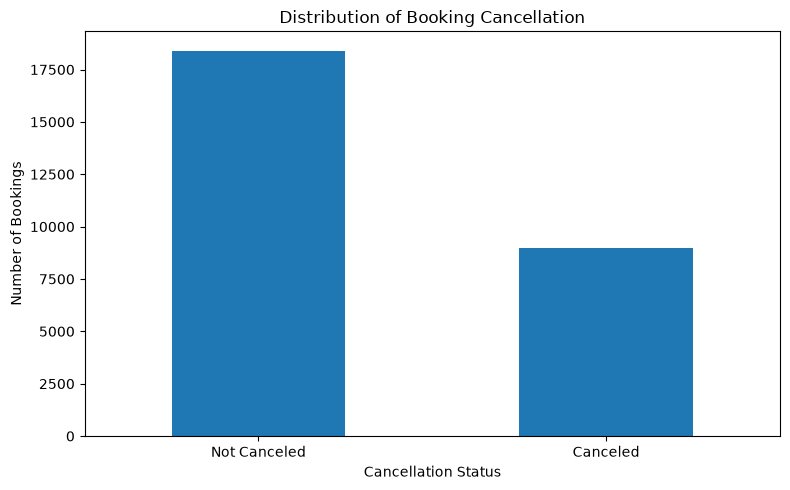

In [8]:
target_counts = train["is_canceled"].value_counts().sort_index()
ax = target_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title("Distribution of Booking Cancellation")
ax.set_xlabel("Cancellation Status")
ax.set_ylabel("Number of Bookings")
ax.set_xticklabels(["Not Canceled", "Canceled"], rotation=0)
plt.tight_layout()
plt.show()

Variabel target is_canceled menunjukkan ketidakseimbangan kelas dengan 67,23% pemesanan tidak dibatalkan (0) dan 32,77% pemesanan dibatalkan (1).

## 5. Data Quality Analysis

Bagian ini penting untuk mengetahui apakah ada data yang hilang, data yang terduplikat, data yang rusak, atau data yang outlier

### Missing Values

In [9]:
missing = pd.DataFrame({
    "Train Missing (%)": train.isna().mean() * 100,
    "Test Missing (%)": test.isna().mean() * 100,
})

missing = missing.fillna(0)

missing = missing[
    (missing["Train Missing (%)"] > 0) |
    (missing["Test Missing (%)"] > 0)
]

missing = missing.sort_values(
    "Train Missing (%)",
    ascending=False
)

display(missing.round(2))

,Train Missing (%),Test Missing (%)
num_children,11.09,10.91
special_requests,9.13,8.66
nightly_rate_idr,7.45,7.89
meal_package,6.43,6.46
days_before_arrival,4.10,4.24
needs_parking,3.95,3.61
room_category,3.66,3.54
num_adults,2.96,2.63


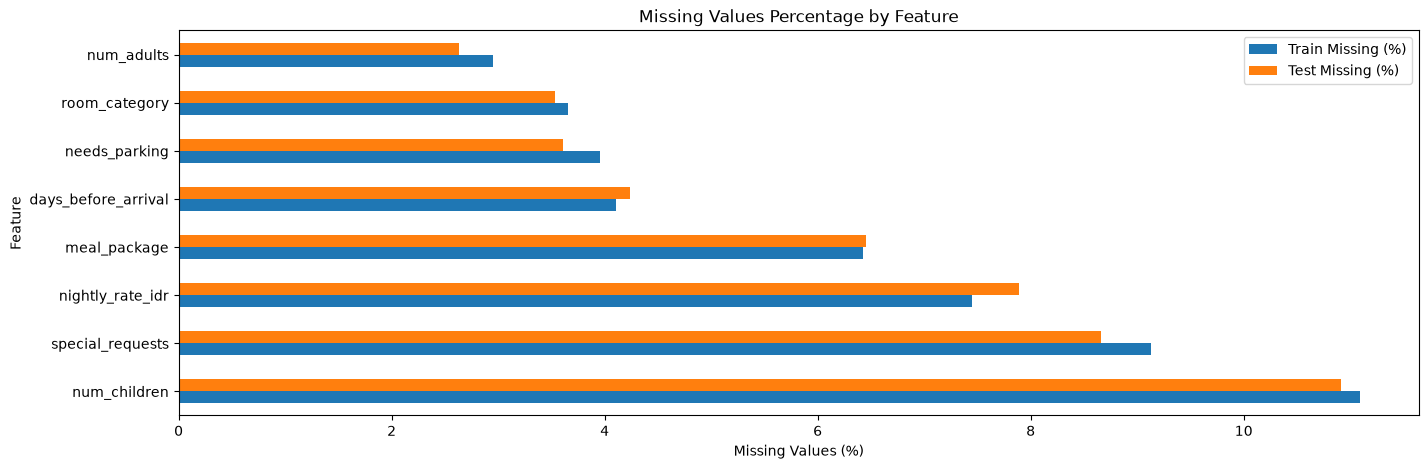

In [10]:
missing[[
    "Train Missing (%)",
    "Test Missing (%)"
]].plot(
    kind="barh",
    figsize=(16, 5),
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.show()

### Duplikasi data

In [11]:
print("Train Duplicate IDs:", train["id"].duplicated().sum())
print("Test Duplicate IDs:", test["id"].duplicated().sum())

Train Duplicate IDs: 0
Test Duplicate IDs: 0


### Validity check
Pemeriksaan yang dilakukan antara lain:
- Feature yang bertipe data integer/float memiliki nilai negatif
- Variabel binary memiliki nilai selain 0 dan 1
- Tanggal kedatangan tidak valid
- Total tamu bernilai nol atau negatif

In [12]:
# Kolom yang seharusnya tidak bernilai negatif
non_negative_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

# Kolom yang hanya boleh bernilai 0 atau 1
binary_cols = [
    "needs_parking",
    "is_returning_guest",
]

def check_validity(df):
    checks = {}

    # Pemeriksaan nilai negatif
    for col in non_negative_cols:
        checks[f"{col}: Negative Values"] = (df[col] < 0).sum()

    # Pemeriksaan variabel binary
    for col in binary_cols:
        checks[f"{col}: Invalid Binary Values"] = (
            df[col].notna() & ~df[col].isin([0, 1])
        ).sum()

    if "is_canceled" in df.columns:
        checks["is_canceled: Invalid Binary Values"] = (
            df["is_canceled"].notna() & ~df["is_canceled"].isin([0, 1])
        ).sum()

    # Pemeriksaan total tamu
    total_guests = df["num_adults"] + df["num_children"]
    checks["Zero Total Guests"] = (total_guests == 0).sum()

    # Pemeriksaan validitas tanggal kedatangan
    date_cols = ["arrival_year", "arrival_month", "arrival_day"]
    date_parts = df[date_cols].rename(columns={
        "arrival_year": "year",
        "arrival_month": "month",
        "arrival_day": "day"
    })
    dates = pd.to_datetime(date_parts, errors="coerce")
    checks["Invalid Arrival Dates"] = (
        df[date_cols].notna().all(axis=1) & dates.isna()
    ).sum()

    return pd.Series(checks)

# Membandingkan train dan test
validity = pd.DataFrame({
    "Train": check_validity(train),
    "Test": check_validity(test)
})

display(validity)

,Train,Test
Invalid Arrival Dates,0,0.0
Zero Total Guests,0,0.0
days_before_arrival: Negative Values,0,0.0
is_canceled: Invalid Binary Values,0,NaN
is_returning_guest: Invalid Binary Values,0,0.0
needs_parking: Invalid Binary Values,0,0.0
nightly_rate_idr: Negative Values,0,0.0
num_adults: Negative Values,0,0.0
num_children: Negative Values,0,0.0
prior_cancellations: Negative Values,0,0.0


### Outlier

In [13]:
# Memilih fitur numerik, kecuali fitur kalender
excluded_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

numeric_cols = [
    col for col in train.columns
    if variable_types.get(col) == "integer"
    and col not in excluded_cols
]

def check_outliers(df):
    results = []

    for col in numeric_cols:
        data = df[col].dropna()

        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        if IQR == 0:
            outlier_count = None
            outlier_pct = None
        else:
            outliers = (
                (data < lower_bound) |
                (data > upper_bound)
            )

            outlier_count = outliers.sum()
            outlier_pct = outliers.mean() * 100

        results.append({
            "Feature": col,
            "Min": data.min(),
            "Max": data.max(),
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": outlier_count,
            "Outlier (%)": outlier_pct,
            "Status": "IQR Not Applied" if IQR == 0 else "IQR Applied"
        })

    return pd.DataFrame(results)

In [14]:
print("Train Outliers:")
display(check_outliers(train).round(2))

print("Test Outliers:")
display(check_outliers(test).round(2))

Train Outliers:


,Feature,Min,Max,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier (%),Status
0,num_adults,0.0,4.0,2.0,2.0,0.0,2.0,2.0,NaN,NaN,IQR Not Applied
1,num_children,0.0,10.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
2,weekend_nights,0.0,7.0,0.0,2.0,2.0,-3.0,5.0,16.0,0.06,IQR Applied
3,weekday_nights,0.0,17.0,1.0,3.0,2.0,-2.0,6.0,258.0,0.94,IQR Applied
4,days_before_arrival,0.0,448.0,17.0,126.0,109.0,-146.5,289.5,916.0,3.49,IQR Applied
5,prior_cancellations,0.0,13.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
6,prior_completed_bookings,0.0,58.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
7,nightly_rate_idr,0.0,9165000.0,1338000.0,2019000.0,681000.0,316500.0,3040500.0,1144.0,4.52,IQR Applied
8,special_requests,0.0,5.0,0.0,1.0,1.0,-1.5,2.5,563.0,2.26,IQR Applied


Test Outliers:


,Feature,Min,Max,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier (%),Status
0,num_adults,0.0,4.0,2.0,2.0,0.0,2.0,2.0,NaN,NaN,IQR Not Applied
1,num_children,0.0,3.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
2,weekend_nights,0.0,6.0,0.0,2.0,2.0,-3.0,5.0,4.0,0.06,IQR Applied
3,weekday_nights,0.0,17.0,1.0,3.0,2.0,-2.0,6.0,50.0,0.73,IQR Applied
4,days_before_arrival,0.0,443.0,17.0,125.0,108.0,-145.0,287.0,274.0,4.18,IQR Applied
5,prior_cancellations,0.0,13.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
6,prior_completed_bookings,0.0,53.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,IQR Not Applied
7,nightly_rate_idr,0.0,5700000.0,1340000.0,2010250.0,670250.0,334625.0,3015625.0,257.0,4.08,IQR Applied
8,special_requests,0.0,5.0,0.0,1.0,1.0,-1.5,2.5,146.0,2.34,IQR Applied


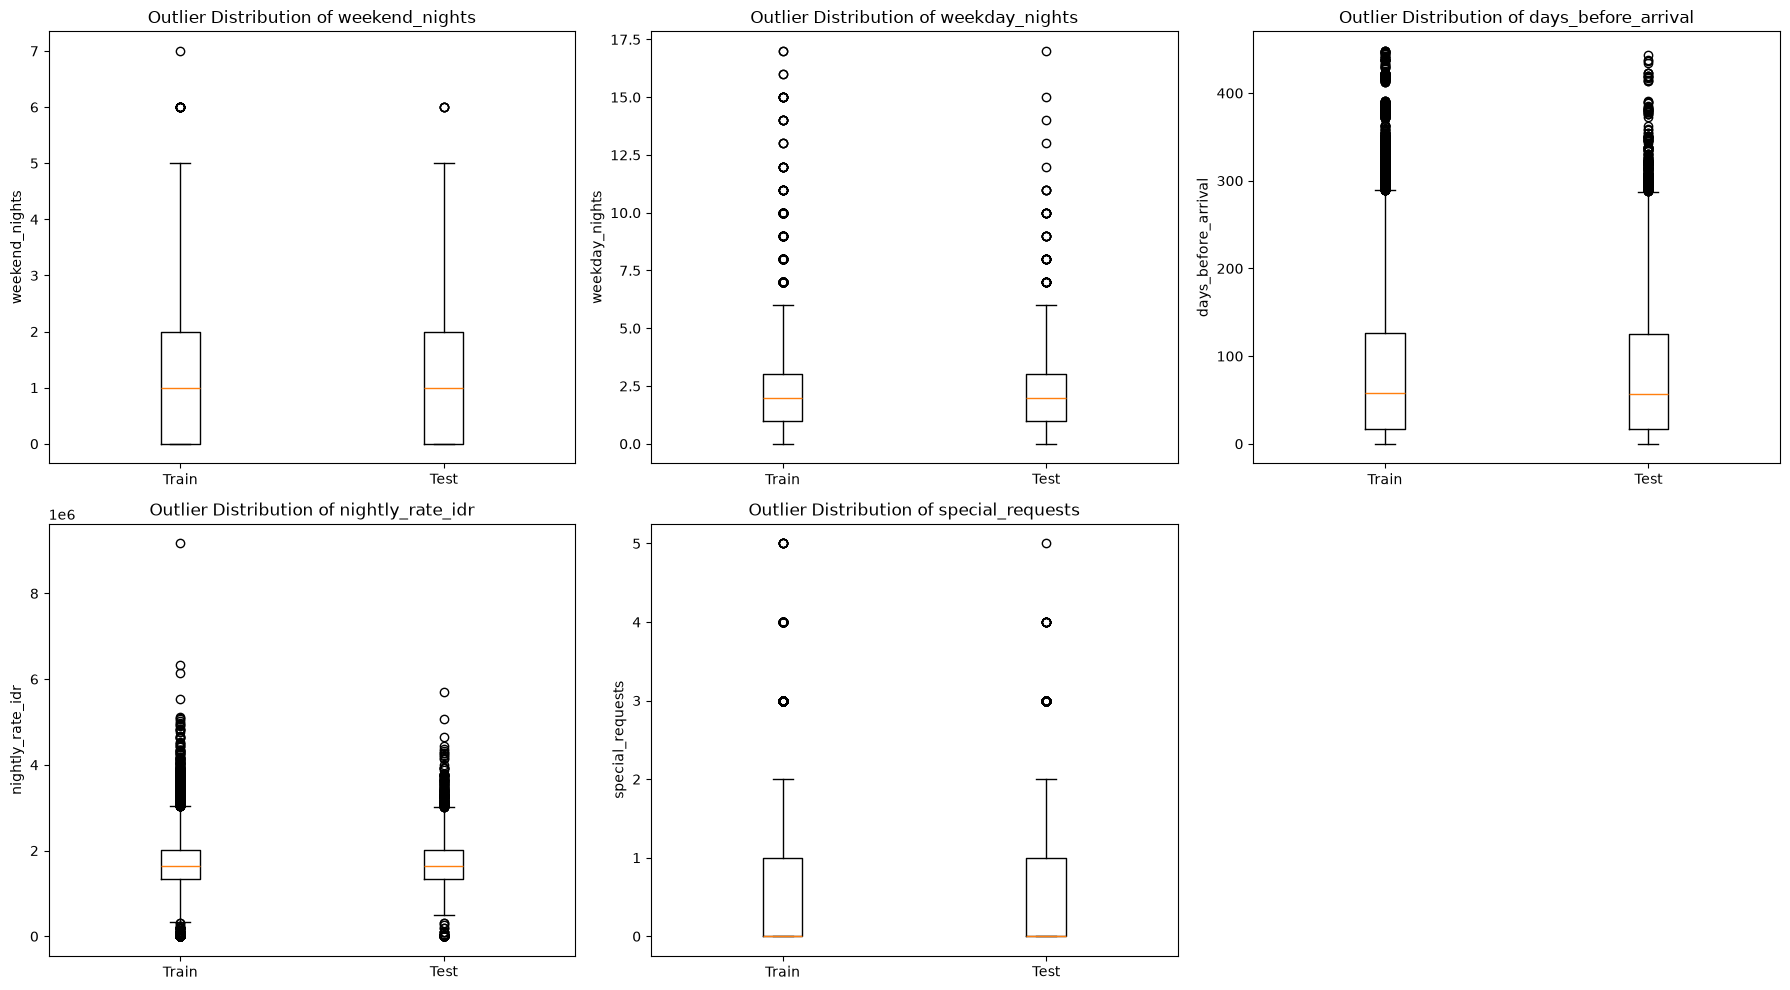

In [15]:
outlier_summary = check_outliers(train)

outlier_cols = outlier_summary.loc[
    outlier_summary["Status"] == "IQR Applied",
    "Feature"
].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, ax in zip(outlier_cols, axes.flat):
    ax.boxplot(
        [
            train[col].dropna(),
            test[col].dropna()
        ],
        tick_labels=["Train", "Test"],
        showfliers=True
    )

    ax.set_title(f"Outlier Distribution of {col}")
    ax.set_ylabel(col)

for ax in axes.flat[len(outlier_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

Terkait dengan kualitas data ini menunjukkan bahwa terdapat delapan fitur dengan missing values (num_children, special_requests, nightly_rate_idr, meal_package, days_before_arrival, needs_parking, room_category, num_adults), tetapi tidak ditemukan duplikasi ID dan pada nilai yang tersedia tidak ditemukan pelanggaran validitas. Beberapa fitur juga memiliki nilai outlier berdasarkan IQR tetapi masih belum menunjukkan kesalahan data.

## 6. Univariate Analysis
Analisis ini bertujuan untuk memahami distribusi dan karakteristik setiap fitur secara individual

### Descriptive Statistic

In [16]:
# Memilih fitur numerik, kecuali fitur kalender
excluded_cols = [
    "arrival_month",
    "arrival_day",
    "arrival_year"
]

numerical_cols = [
    col for col in train.columns
    if variable_types.get(col) == "integer"
    and col not in excluded_cols
]

# Statistik deskriptif
display(train[numerical_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
prior_cancellations,27373.0,0.02,0.36,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,27373.0,0.14,1.69,0.0,0.0,0.0,0.0,58.0
nightly_rate_idr,25335.0,1716979.55,587936.77,0.0,1338000.0,1644000.0,2019000.0,9165000.0
special_requests,24873.0,0.67,0.80,0.0,0.0,0.0,1.0,5.0


### Distribusi Numerik

In [17]:
low_unique_cols = [
    col for col in numerical_cols
    if train[col].nunique() < 10
]

for col in low_unique_cols:
    print(f"\nFeature: {col}")
    counts = train[col].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": counts / len(train) * 100
    })
    display(summary.round(2))


Feature: num_adults


,Count,Percentage (%)
num_adults,,
2.0,19164,70.01
1.0,5604,20.47
3.0,1675,6.12
NaN,809,2.96
0.0,106,0.39
4.0,15,0.05



Feature: num_children


,Count,Percentage (%)
num_children,,
0.0,22318,81.53
NaN,3035,11.09
1.0,1221,4.46
2.0,780,2.85
3.0,16,0.06
9.0,2,0.01
10.0,1,0.00



Feature: weekend_nights


,Count,Percentage (%)
weekend_nights,,
0,12715,46.45
1,7493,27.37
2,6894,25.19
3,119,0.43
4,110,0.40
5,26,0.09
6,15,0.05
7,1,0.00



Feature: prior_cancellations


,Count,Percentage (%)
prior_cancellations,,
0,27132,99.12
1,143,0.52
2,33,0.12
3,30,0.11
11,19,0.07
5,7,0.03
4,6,0.02
13,2,0.01
6,1,0.00



Feature: special_requests


,Count,Percentage (%)
special_requests,,
0.0,12730,46.51
1.0,8334,30.45
2.0,3246,11.86
NaN,2500,9.13
3.0,496,1.81
4.0,60,0.22
5.0,7,0.03


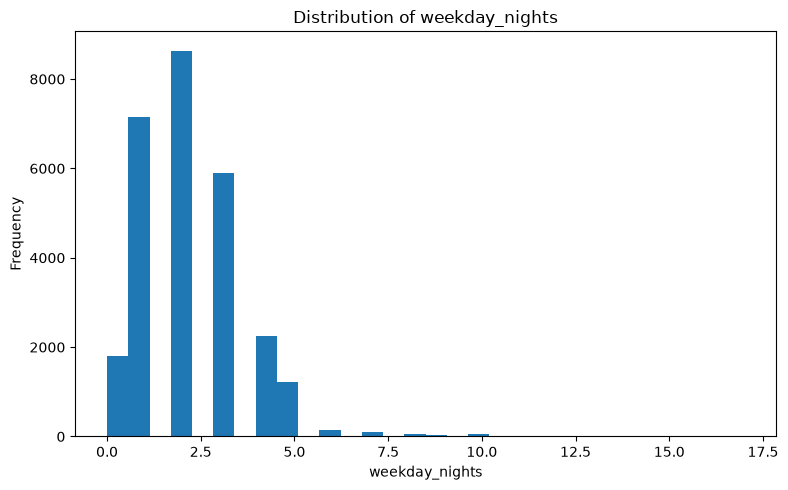

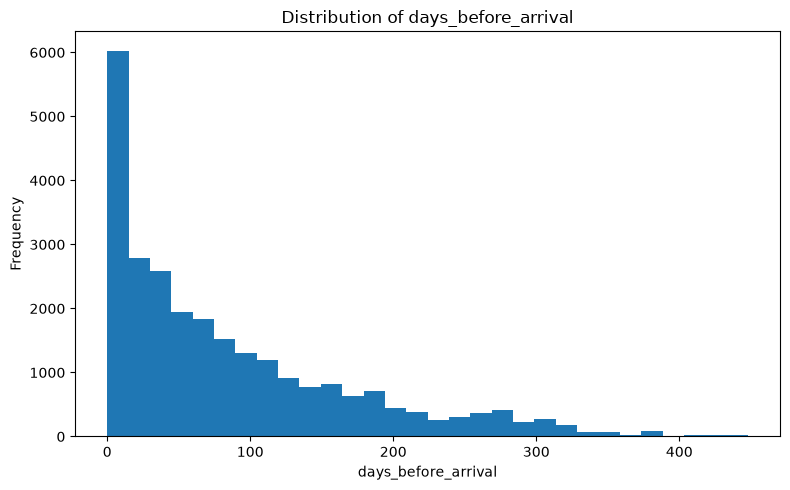

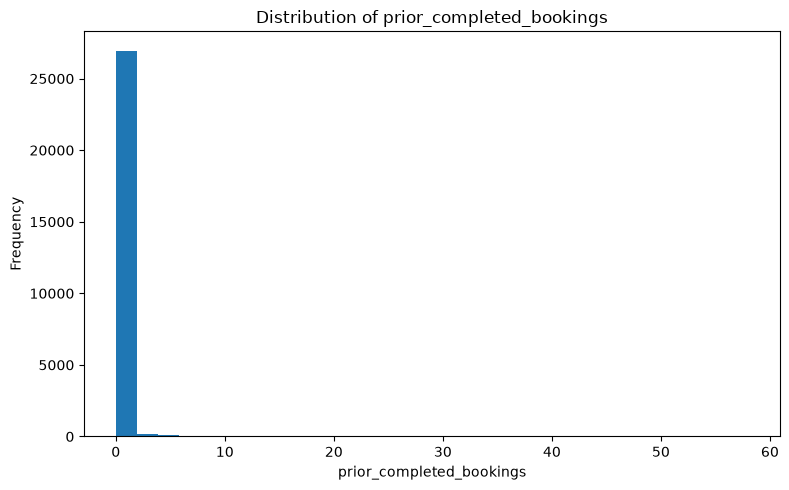

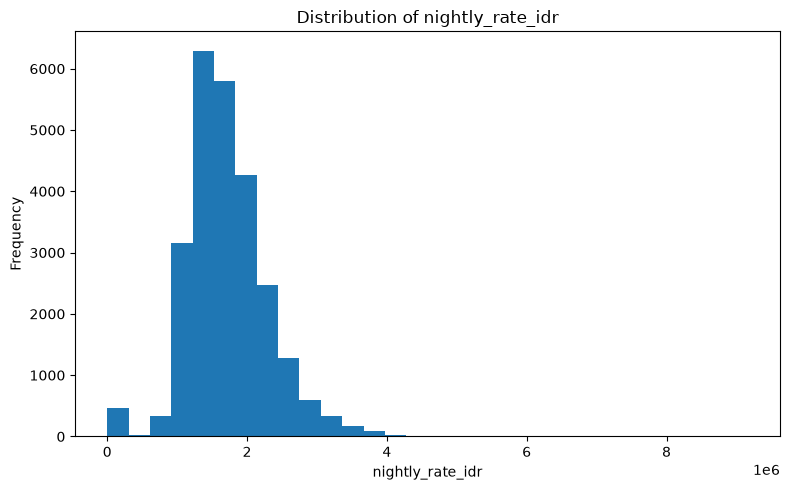

In [18]:
high_unique_cols = [
    col for col in numerical_cols
    if train[col].nunique() >= 10
]

for col in high_unique_cols:
    plt.figure(figsize=(8, 5))
    plt.hist(train[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

Pada distribusi ini menunjukkan bahwa sebagian besar dari pemesanan tersebut hanya melibatkan dua orang dewasa dan tidak menyertakan anak-anak. Jumlah menginap cenderung terkonsentrasi pada durasi yang pendek yaitu pada weekend_nights terkonsentrasi 0-2 malam dan weekdays_nights terkonsentrasi 1-3 malam.

Fitur days_before_arrival menunjukkan distribusi right-skewed dengan median 58 hari dan nilai maksimum 448 hari. Sementara itu, prior_cancellations sangat didominasi oleh nilai nol sebesar 99.12% dan prior_completed_bookings juga sangat didominasi nilai nol secara grafik.

Fitur nightly_rate_idr memiliki median Rp1.644.000 dan nilai maksimum Rp9.165.000 yang menunjukkan adanya nilai tarif yang jauh lebih tinggi dibandingkan sebagian besar observasi.

### Distribusi Kategori

In [19]:
categorical_cols = [
    col for col in train.columns
    if variable_types.get(col) in ["categorical", "binary"]
    and col != "is_canceled"
]

for col in categorical_cols:
    counts = train[col].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": counts / len(train) * 100
    })
    print(f"\nFeature: {col}")
    display(summary.round(2))


Feature: meal_package


,Count,Percentage (%)
meal_package,,
Breakfast,19654,71.80
Room Only,3713,13.56
Half Board,2242,8.19
NaN,1760,6.43
Full Board,4,0.01



Feature: needs_parking


,Count,Percentage (%)
needs_parking,,
0.0,25497,93.15
NaN,1082,3.95
1.0,794,2.90



Feature: room_category


,Count,Percentage (%)
room_category,,
Type B,20447,74.70
Type G,4396,16.06
NaN,1002,3.66
Type A,699,2.55
Type D,514,1.88
Type C,189,0.69
Type F,119,0.43
Type E,7,0.03



Feature: booking_channel


,Count,Percentage (%)
booking_channel,,
Online Travel Agent,17511,63.97
Offline Agent,7960,29.08
Corporate,1513,5.53
Complimentary,301,1.10
Airline,88,0.32



Feature: is_returning_guest


,Count,Percentage (%)
is_returning_guest,,
0,26684,97.48
1,689,2.52


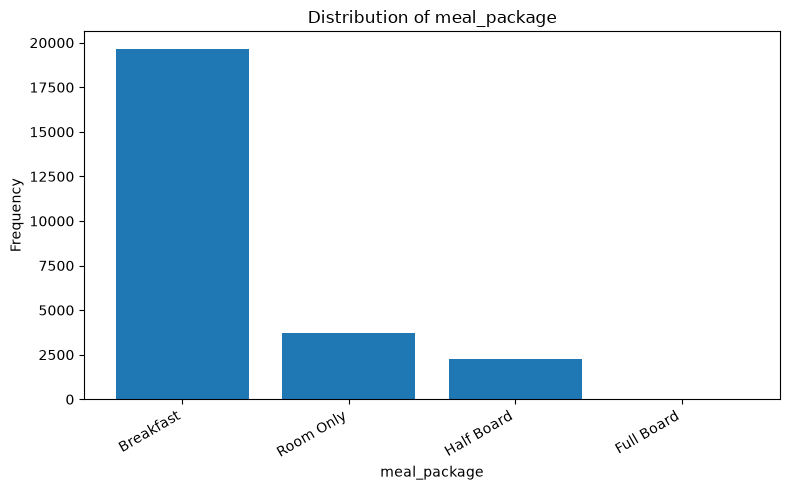

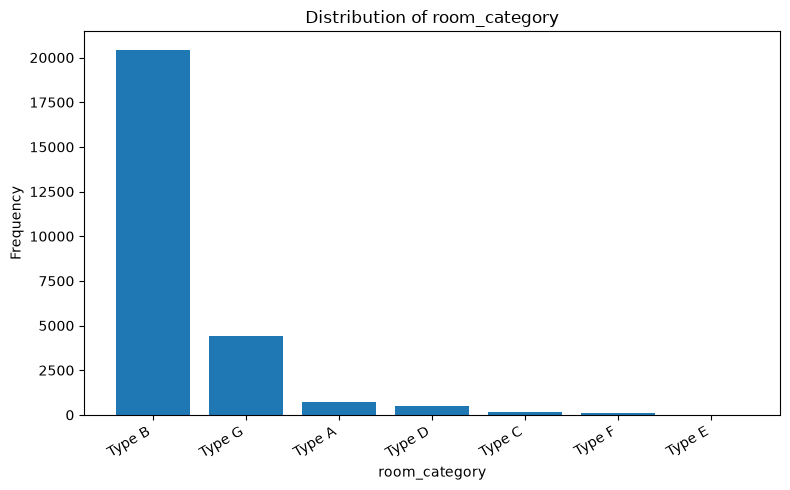

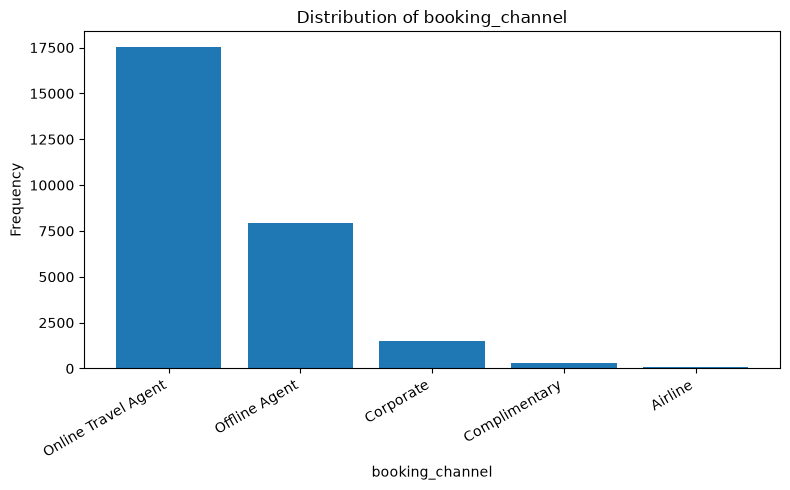

In [20]:
categorical_only = [
    col for col in categorical_cols
    if variable_types.get(col) == "categorical"
]

for col in categorical_only:
    counts = train[col].value_counts()
    plt.figure(figsize=(8, 5))
    plt.bar(
        counts.index.astype(str).tolist(),
        counts.tolist()
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

Distribusi fitur kategorikal menunjukkan bahwa sebagian besar pemesanan menggunakan paket Breakfast (71,80%), memilih kamar B (74,40%), dan melalui Online Travel Agent (63,97%) untuk booking. Selain itu, sebagian besar pemesan tidak membutuhkan parkir (0 sebesar 93,13%) dan berasal dari tamu yang belum pernah menginap sebelumnya (97,48%).

### Distribusi temporal

In [21]:
temporal_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

for col in temporal_cols:
    counts = train[col].value_counts().sort_index()
    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": counts / len(train) * 100
    })
    print(f"\nFeature: {col}")
    display(summary.round(2))


Feature: arrival_year


,Count,Percentage (%)
arrival_year,,
2023,4924,17.99
2024,22449,82.01



Feature: arrival_month


,Count,Percentage (%)
arrival_month,,
1,777,2.84
2,1336,4.88
3,1786,6.52
4,2066,7.55
5,1935,7.07
6,2462,8.99
7,2198,8.03
8,2843,10.39
9,3458,12.63



Feature: arrival_day


,Count,Percentage (%)
arrival_day,,
1,965,3.53
2,961,3.51
3,863,3.15
4,924,3.38
5,1014,3.70
6,858,3.13
7,895,3.27
8,827,3.02
9,836,3.05


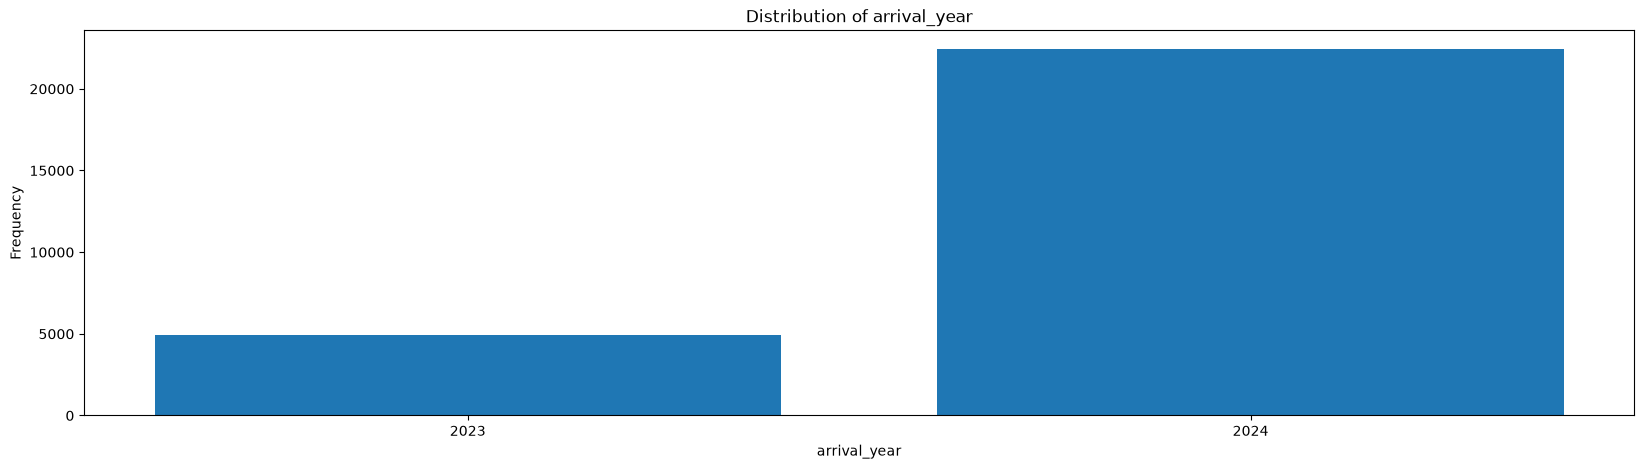

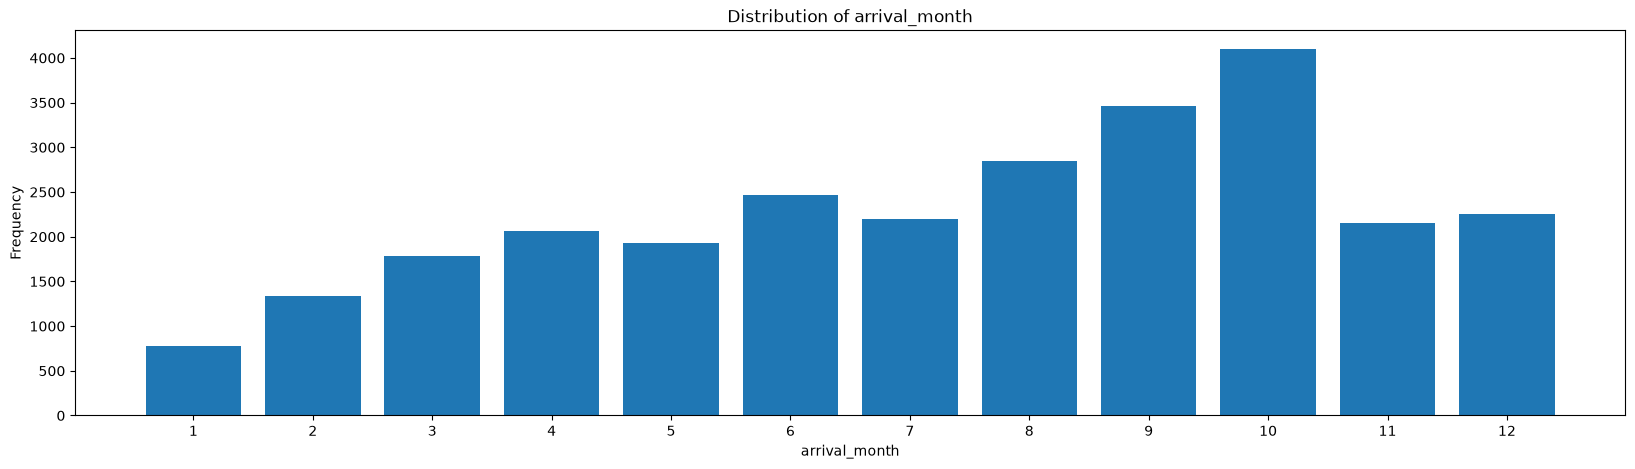

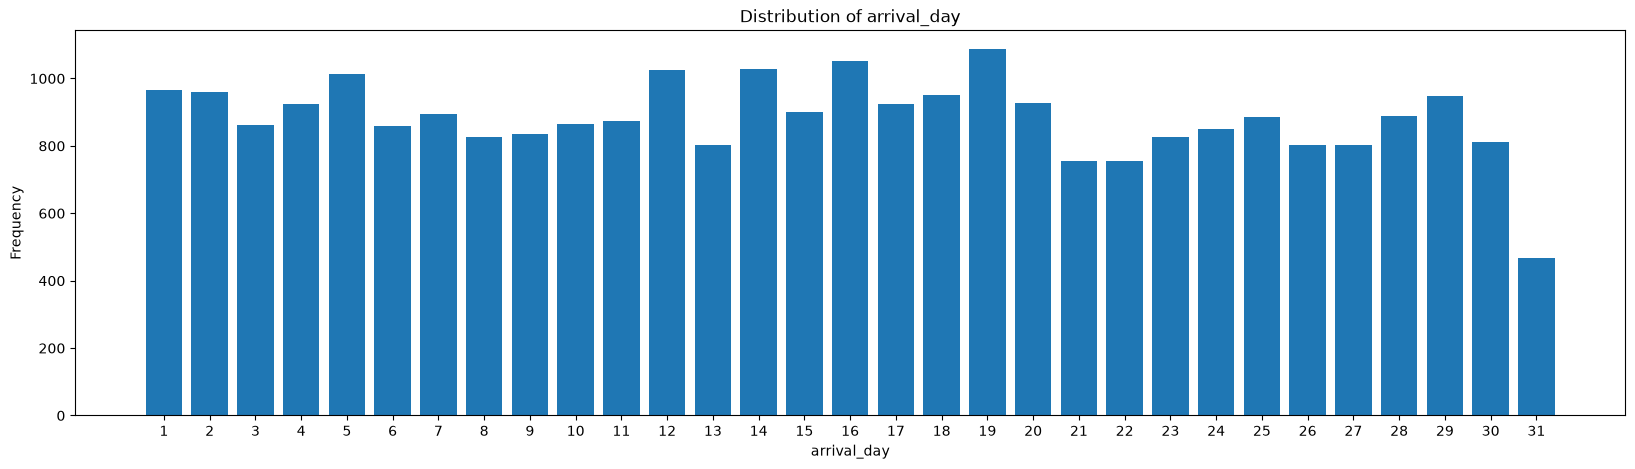

In [22]:
for col in temporal_cols:
    counts = train[col].value_counts().sort_index()
    plt.figure(figsize=(20, 5))
    plt.bar(
        counts.index.astype(str).tolist(),
        counts.tolist()
    )
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

Pada distribusi temporal, sebagian besar pemesanan memiliki tahun datang 2024 (82,01%) dan bulan datang nya memiliki frekuensi tertinggi pada Oktober (14,99%) dan terendah pada Januari (2,84%). Distribusi hari kedatangan merata pada 1-30, sementara tanggal 31 memiliki frekuensi terendah karena tidak semua bulan memiliki 31 hari.

## 7. Bivariate & Multivariate Analysis

Analisis ini bertujuan untuk mengidentifikasi hubungan antara fitur dengan variabel target is_canceled, serta hubungan antarfitur dalam dataset.

### Kategorikal vs Target

,booking_count,canceled_count,cancellation_rate
booking_channel,,,
Airline,88,27,30.68
Complimentary,301,0,0.00
Corporate,1513,174,11.50
Offline Agent,7960,2400,30.15
Online Travel Agent,17511,6368,36.37


,booking_count,canceled_count,cancellation_rate
meal_package,,,
Breakfast,19654,6121,31.14
Full Board,4,1,25.00
Half Board,2242,1030,45.94
Room Only,3713,1255,33.80
NaN,1760,562,31.93


,booking_count,canceled_count,cancellation_rate
room_category,,,
Type A,699,298,42.63
Type B,20447,6572,32.14
Type C,189,47,24.87
Type D,514,169,32.88
Type E,7,2,28.57
Type F,119,29,24.37
Type G,4396,1503,34.19
NaN,1002,349,34.83


,booking_count,canceled_count,cancellation_rate
needs_parking,,,
0.0,25497,8551,33.54
1.0,794,80,10.08
NaN,1082,338,31.24


,booking_count,canceled_count,cancellation_rate
is_returning_guest,,,
0,26684,8959,33.57
1,689,10,1.45


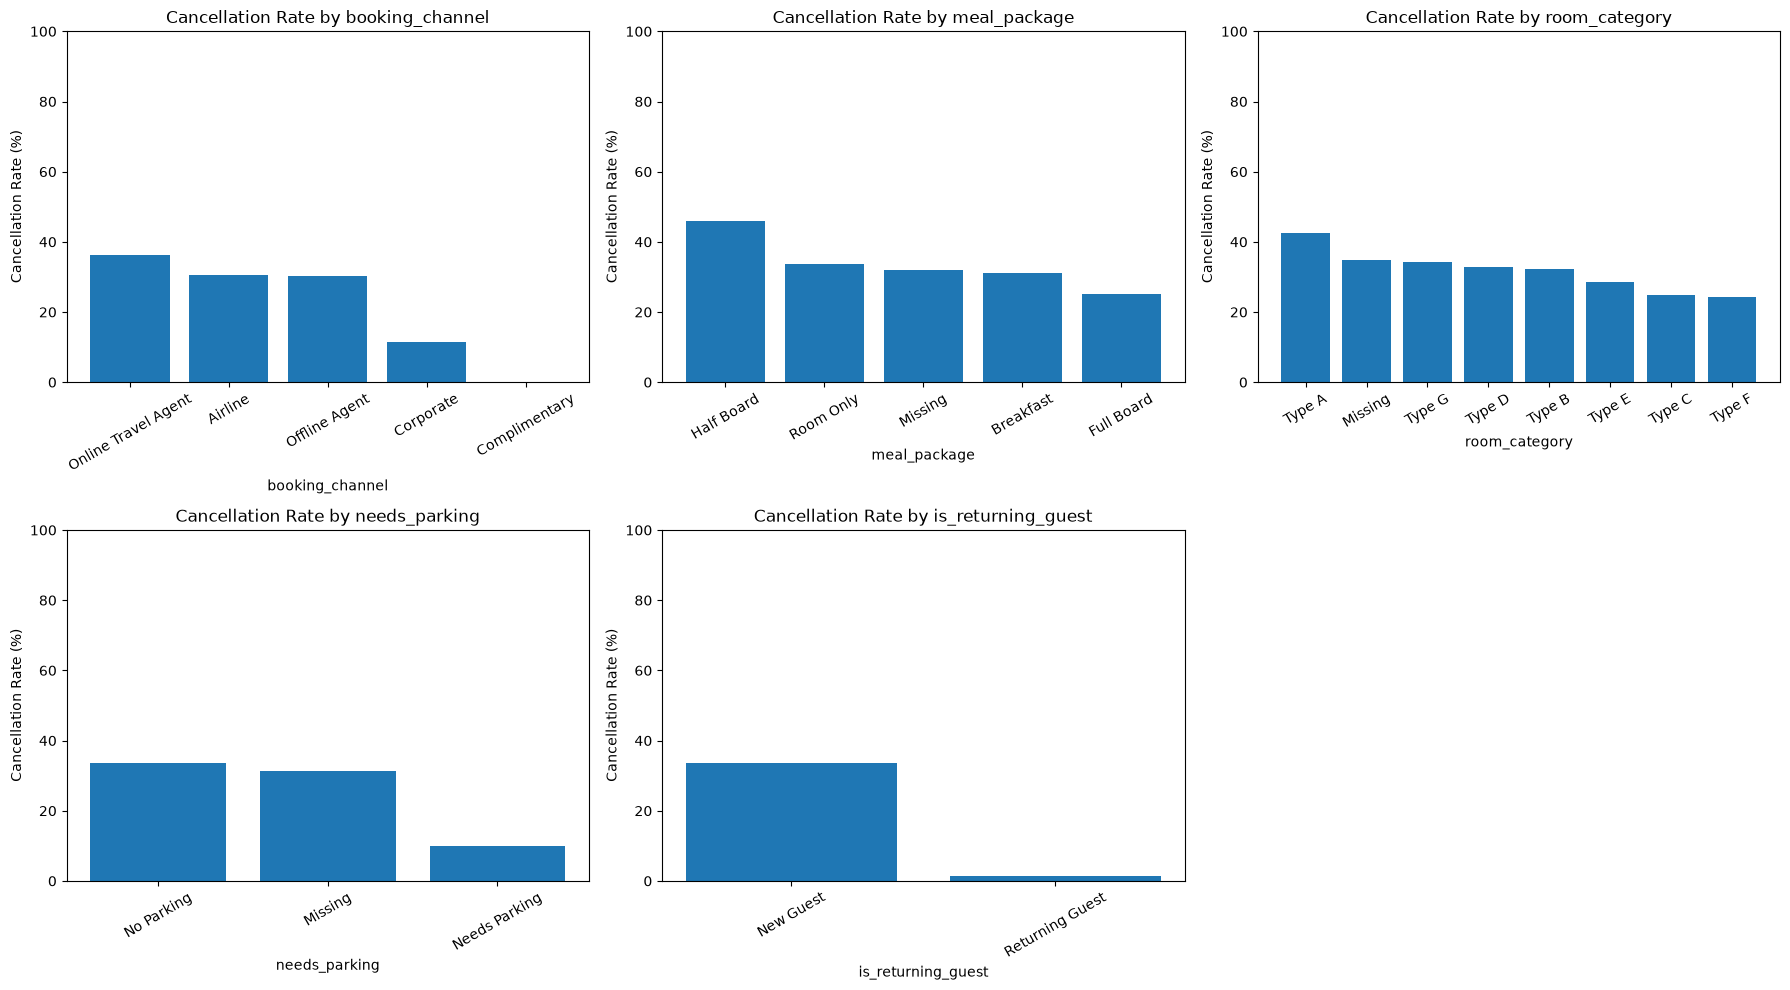

In [23]:
categorical_cols = [
    "booking_channel",
    "meal_package",
    "room_category",
    "needs_parking",
    "is_returning_guest"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, ax in zip(categorical_cols, axes.flat):
    analysis = (
        train.groupby(col, dropna=False)["is_canceled"]
        .agg(
            booking_count="count",
            canceled_count="sum",
            cancellation_rate="mean"
        )
    )

    analysis["cancellation_rate"] *= 100
    display(analysis.round(2))

    analysis_plot = pd.DataFrame(analysis).sort_values(
        "cancellation_rate",
        ascending=False
    )

    labels = analysis_plot.index.to_series().astype("string").fillna("Missing")

    if col == "needs_parking":
        labels = labels.replace({
            "0.0": "No Parking",
            "1.0": "Needs Parking"
        })

    elif col == "is_returning_guest":
        labels = labels.replace({
            "0": "New Guest",
            "1": "Returning Guest"
        })

    ax.bar(
        labels,
        analysis_plot["cancellation_rate"]
    )

    ax.set_title(f"Cancellation Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Cancellation Rate (%)")
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, 100)

for ax in axes.flat[len(categorical_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

Pada kanal pemesanan, kanal Online Travel Agent memiliki tingkat pembatalan sebesar 36,37%. Berdasarkan paket makanan, Half Board memiliki tingkat pembatalan tertinggi sebesar 45,94%, sedangkan pada kategori kamar, Tipe A memiliki tingkat pembatalan tertinggi sebesar 42,63%.

Pemesanan yang tidak membutuhkan parkir lebih besar tingkat pembatalannya (33,54%) dibandingkan dengan pemesanan yang membutuhkan parkir (10,08%). Tamu yang belum pernah menginap sebelumnya memiliki tingkat pembatalan jauh lebih tinggi (33,57%) dibandingkan tamu yang pernah menginap sebelumnya (1,45%)

### Numerikal vs Target

In [24]:
low_unique_cols = [
    col for col in numerical_cols
    if train[col].nunique() < 10
]

for col in low_unique_cols:
    analysis = (
        train.groupby(col, dropna=False)["is_canceled"]
        .agg(
            booking_count="count",
            canceled_count="sum",
            cancellation_rate="mean"
        )
    )
    analysis["cancellation_rate"] *= 100
    print(f"\nFeature: {col}")
    display(analysis.round(2))


Feature: num_adults


,booking_count,canceled_count,cancellation_rate
num_adults,,,
0.0,106,32,30.19
1.0,5604,1358,24.23
2.0,19164,6664,34.77
3.0,1675,641,38.27
4.0,15,3,20.00
NaN,809,271,33.50



Feature: num_children


,booking_count,canceled_count,cancellation_rate
num_children,,,
0.0,22318,7236,32.42
1.0,1221,399,32.68
2.0,780,333,42.69
3.0,16,4,25.00
9.0,2,1,50.00
10.0,1,0,0.00
NaN,3035,996,32.82



Feature: weekend_nights


,booking_count,canceled_count,cancellation_rate
weekend_nights,,,
0,12715,3848,30.26
1,7493,2566,34.25
2,6894,2390,34.67
3,119,62,52.10
4,110,69,62.73
5,26,21,80.77
6,15,12,80.00
7,1,1,100.00



Feature: prior_cancellations


,booking_count,canceled_count,cancellation_rate
prior_cancellations,,,
0,27132,8959,33.02
1,143,7,4.90
2,33,0,0.00
3,30,1,3.33
4,6,0,0.00
5,7,0,0.00
6,1,0,0.00
11,19,0,0.00
13,2,2,100.00



Feature: special_requests


,booking_count,canceled_count,cancellation_rate
special_requests,,,
0.0,12730,5500,43.21
1.0,8334,1984,23.81
2.0,3246,464,14.29
3.0,496,0,0.00
4.0,60,0,0.00
5.0,7,0,0.00
NaN,2500,1021,40.84


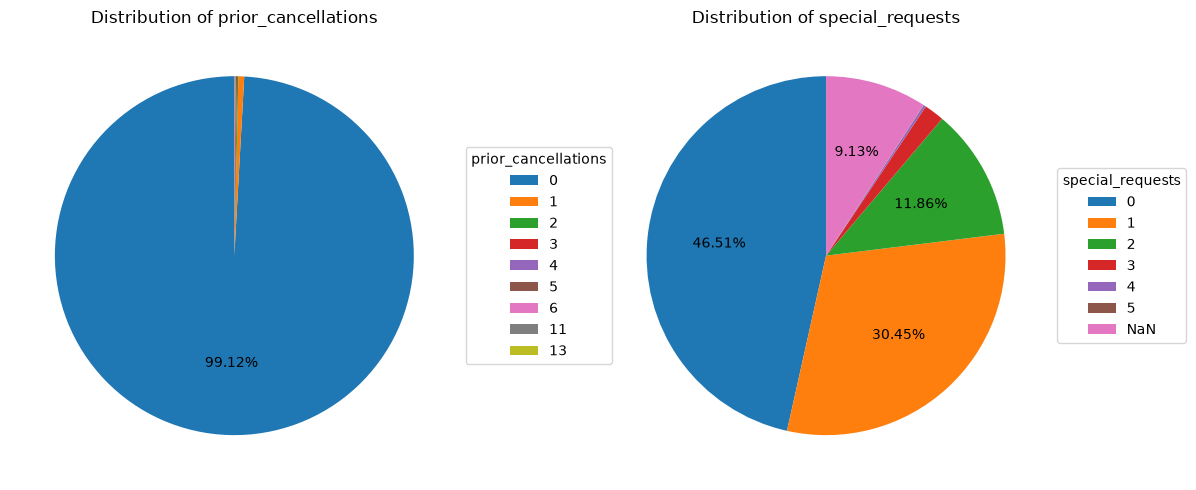

In [25]:
selected_cols = [
    "prior_cancellations",
    "special_requests"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for col, ax in zip(selected_cols, axes.flat):
    counts = train[col].value_counts(dropna=False).sort_index()

    labels = [
        "NaN" if pd.isna(value) else str(int(value))
        for value in counts.index
    ]

    ax.pie(
        counts,
        autopct=lambda pct: f"{pct:.2f}%" if pct >= 2 else "",
        startangle=90
    )

    ax.set_title(f"Distribution of {col}")
    ax.legend(
        labels,
        title=col,
        loc="center left",
        bbox_to_anchor=(1, 0.5)
    )

plt.tight_layout()
plt.show()

In [26]:
high_unique_cols = [
    col for col in numerical_cols
    if train[col].nunique() >= 10
]

for col in high_unique_cols:
    analysis = (
        train.groupby("is_canceled")[col]
        .agg(["count", "mean", "median", "std", "min", "max"])
    )
    print(f"\nFeature: {col}")
    display(analysis.round(2))


Feature: weekday_nights


,count,mean,median,std,min,max
is_canceled,,,,,,
0,18404,2.11,2.0,1.31,0,17
1,8969,2.40,2.0,1.61,0,17



Feature: days_before_arrival


,count,mean,median,std,min,max
is_canceled,,,,,,
0,17631,58.91,38.0,63.72,0.0,390.0
1,8619,139.52,123.0,99.20,0.0,448.0



Feature: prior_completed_bookings


,count,mean,median,std,min,max
is_canceled,,,,,,
0,18404,0.21,0.0,2.06,0,58
1,8969,0.00,0.0,0.13,0,12



Feature: nightly_rate_idr


,count,mean,median,std,min,max
is_canceled,,,,,,
0,17004,1661797.52,1579000.0,602473.15,0.0,6338000.0
1,8331,1829608.93,1773000.0,539895.69,0.0,9165000.0


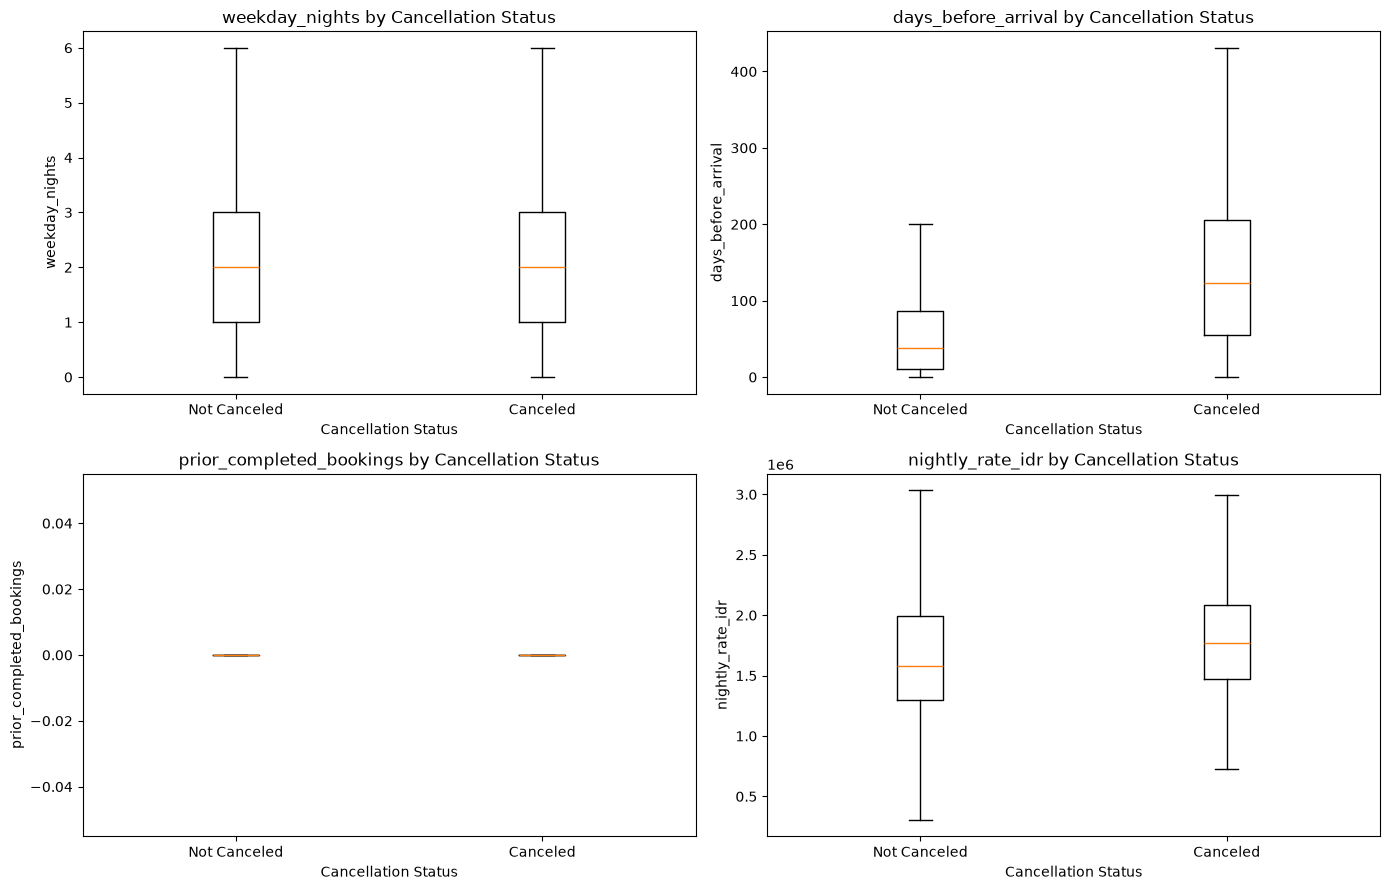

In [27]:
selected_cols = [
    "weekday_nights",
    "days_before_arrival",
    "prior_completed_bookings",
    "nightly_rate_idr"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(selected_cols, axes.flat):
    ax.boxplot(
        [
            train.loc[train["is_canceled"] == 0, col].dropna(),
            train.loc[train["is_canceled"] == 1, col].dropna()
        ],
        tick_labels=["Not Canceled", "Canceled"],
        showfliers=False
    )

    ax.set_title(f"{col} by Cancellation Status")
    ax.set_xlabel("Cancellation Status")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

Fitur days_before_arrival menunjukkan perbedaan yang cukup besar dengan median 123 hari pada pemesanan yang dibatalkan dibandingkan dengan 38 hari pada pemesanan yang tidak dibatalkan. Fitur nightly_rate_idr menunjukkan bahwa pemesanan yang dibatalkan cenderung memiliki tarif kamar yang lebih tinggi dengan median Rp1.773.000 dibandingkan Rp1.579.000 pada pemesanan yang tidak dibatalkan. Tingkat pembatalan cenderung lebih rendah pada pemesanan dengan jumlah special_request yang lebih banyak.

### Temporal vs Target

#### Analisis per hari, per bulan, dan per tahun

In [28]:
temporal_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

for col in temporal_cols:
    analysis = (
        train.groupby(col)["is_canceled"]
        .agg(
            booking_count="count",
            canceled_count="sum",
            cancellation_rate="mean"
        )
    )
    analysis["cancellation_rate"] *= 100
    print(f"\nFeature: {col}")
    display(analysis.round(2))


Feature: arrival_year


,booking_count,canceled_count,cancellation_rate
arrival_year,,,
2023,4924,726,14.74
2024,22449,8243,36.72



Feature: arrival_month


,booking_count,canceled_count,cancellation_rate
arrival_month,,,
1,777,20,2.57
2,1336,342,25.60
3,1786,533,29.84
4,2066,754,36.50
5,1935,716,37.00
6,2462,1003,40.74
7,2198,985,44.81
8,2843,1105,38.87
9,3458,1169,33.81



Feature: arrival_day


,booking_count,canceled_count,cancellation_rate
arrival_day,,,
1,965,271,28.08
2,961,311,32.36
3,863,351,40.67
4,924,251,27.16
5,1014,323,31.85
6,858,280,32.63
7,895,255,28.49
8,827,244,29.50
9,836,227,27.15


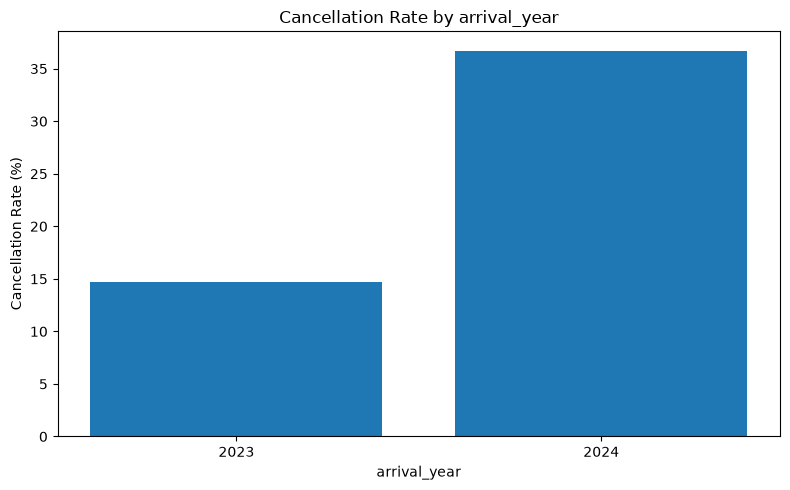

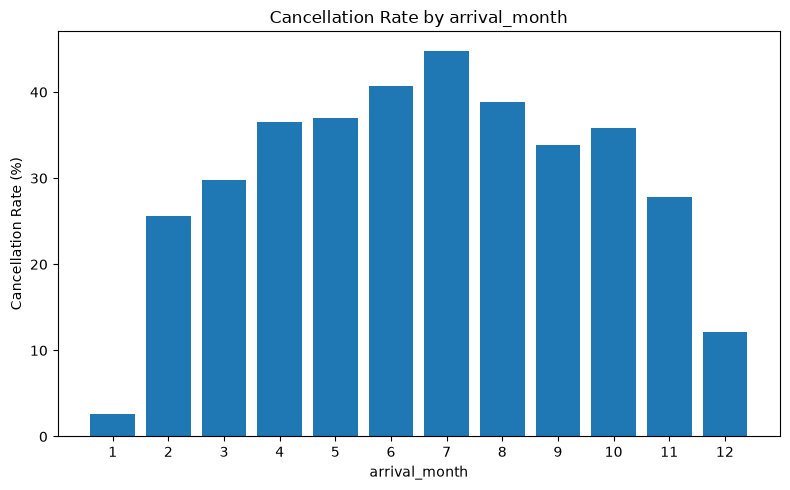

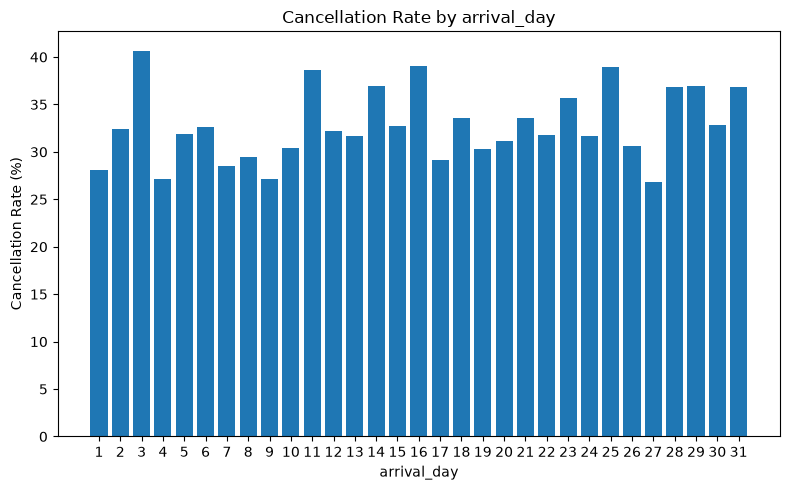

In [29]:
for col in temporal_cols:
    analysis = (
        train.groupby(col)["is_canceled"]
        .agg(
            booking_count="count",
            cancellation_rate="mean"
        )
        .sort_index()
    )

    analysis["cancellation_rate"] *= 100

    plt.figure(figsize=(8, 5))
    plt.bar(
        analysis.index.astype(str).tolist(),
        analysis["cancellation_rate"].tolist()
    )
    plt.title(f"Cancellation Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

#### Analisis per bulan berdasarkan tahun 

In [30]:
monthly_analysis = (
    train.groupby(["arrival_year", "arrival_month"])["is_canceled"]
    .agg(
        booking_count="count",
        cancellation_rate="mean"
    )
)

monthly_analysis["cancellation_rate"] *= 100

display(monthly_analysis.round(2))

booking_count  cancellation_rate
arrival_year arrival_month                                  
2023         7                        274              64.23
             8                        776              18.56
             9                       1241              10.72
             10                      1451              16.20
             11                       463               4.32
             12                       719               2.50
2024         1                        777               2.57
             2                       1336              25.60
             3                       1786              29.84
             4                       2066              36.50
             5                       1935              37.00
             6                       2462              40.74
             7                       1924              42.05
             8                       2067              46.49
             9                       2217              46.73
             10                      2651              46.55
             11                      1696              34.20
             12                      1532              16.64

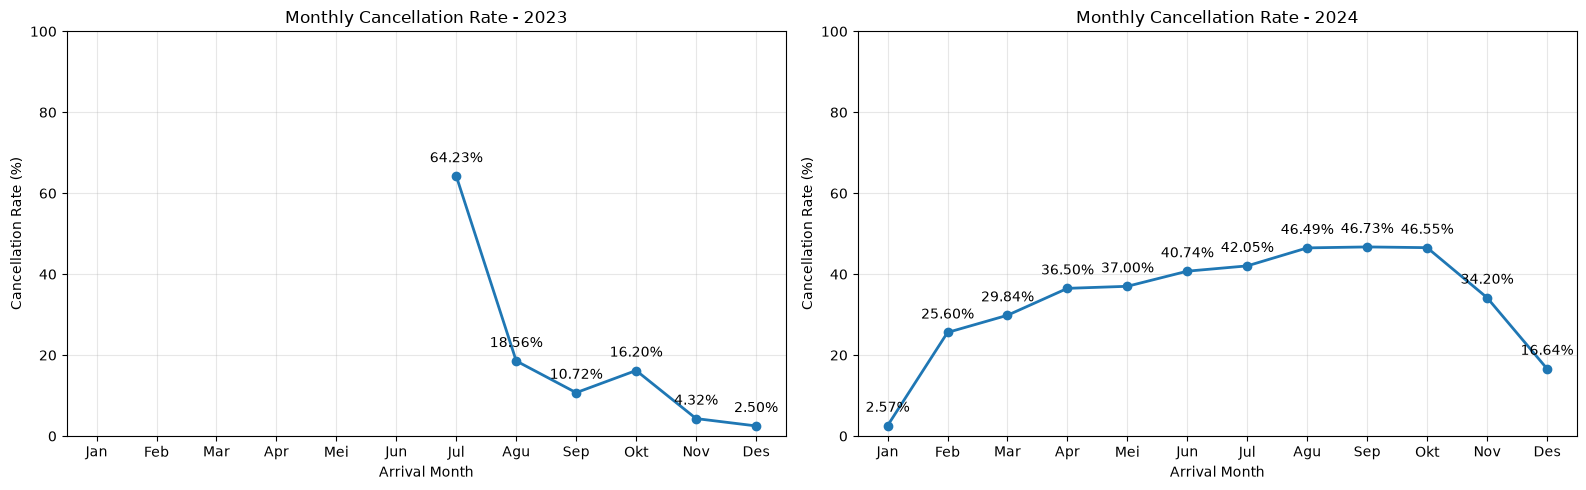

In [31]:
monthly_plot = monthly_analysis.reset_index()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
    "Jul", "Agu", "Sep", "Okt", "Nov", "Des"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for year, ax in zip([2023, 2024], axes.flat):
    subset = monthly_plot[
        monthly_plot["arrival_year"] == year
    ].sort_values("arrival_month")

    ax.plot(
        subset["arrival_month"],
        subset["cancellation_rate"],
        marker="o",
        linewidth=2
    )

    for _, row in subset.iterrows():
        ax.annotate(
            f'{row["cancellation_rate"]:.2f}%',
            (row["arrival_month"], row["cancellation_rate"]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center"
        )

    ax.set_title(f"Monthly Cancellation Rate - {year}")
    ax.set_xlabel("Arrival Month")
    ax.set_ylabel("Cancellation Rate (%)")

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.set_xlim(0.5, 12.5)
    ax.set_ylim(0, 100)

    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

,booking_count,canceled_count,cancellation_rate
arrival_day,,,
1,45,34,75.56
2,3,3,100.00
3,2,1,50.00
4,3,3,100.00
5,2,2,100.00
6,7,7,100.00
7,10,6,60.00
8,6,4,66.67
9,4,3,75.00


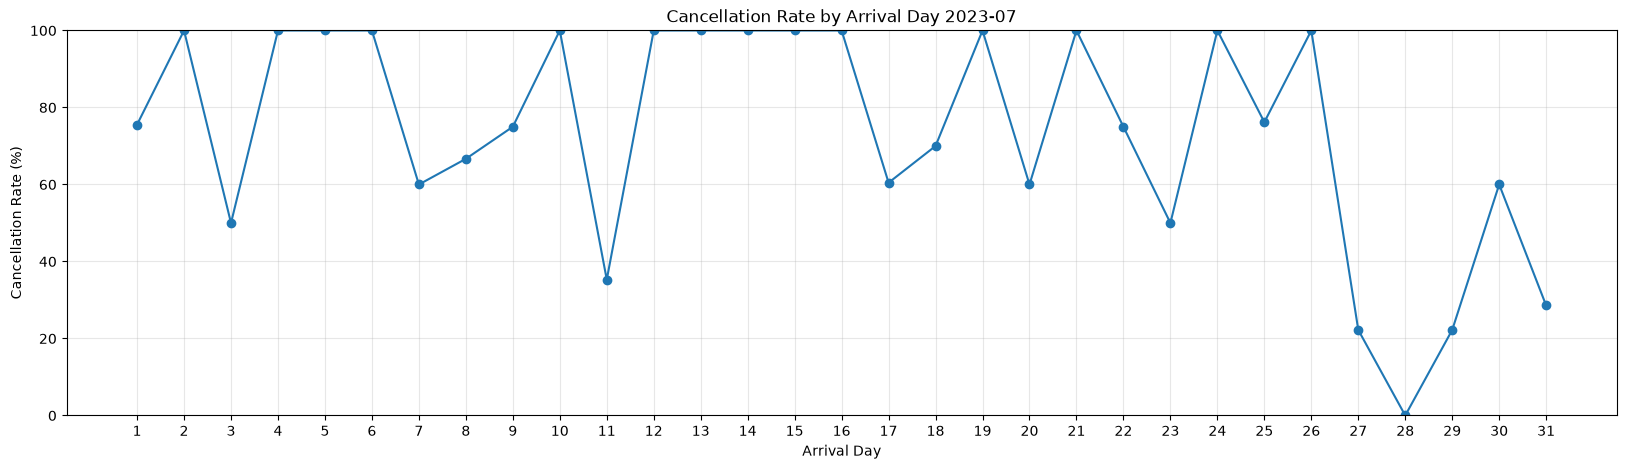

,booking_count,canceled_count,cancellation_rate
arrival_day,,,
1,58,27,46.55
2,72,43,59.72
3,54,25,46.30
4,55,19,34.55
5,64,28,43.75
6,54,22,40.74
7,90,40,44.44
8,54,27,50.00
9,45,23,51.11


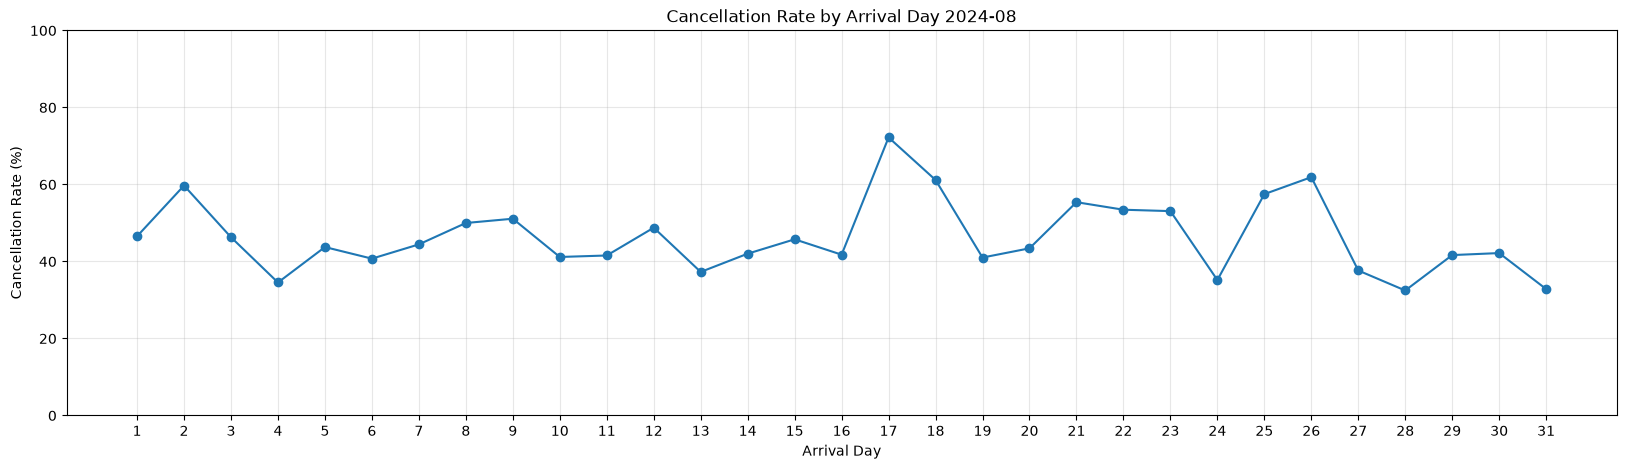

,booking_count,canceled_count,cancellation_rate
arrival_day,,,
1,80,32,40.00
2,58,24,41.38
3,72,29,40.28
4,92,30,32.61
5,42,20,47.62
6,48,14,29.17
7,99,63,63.64
8,73,31,42.47
9,28,9,32.14


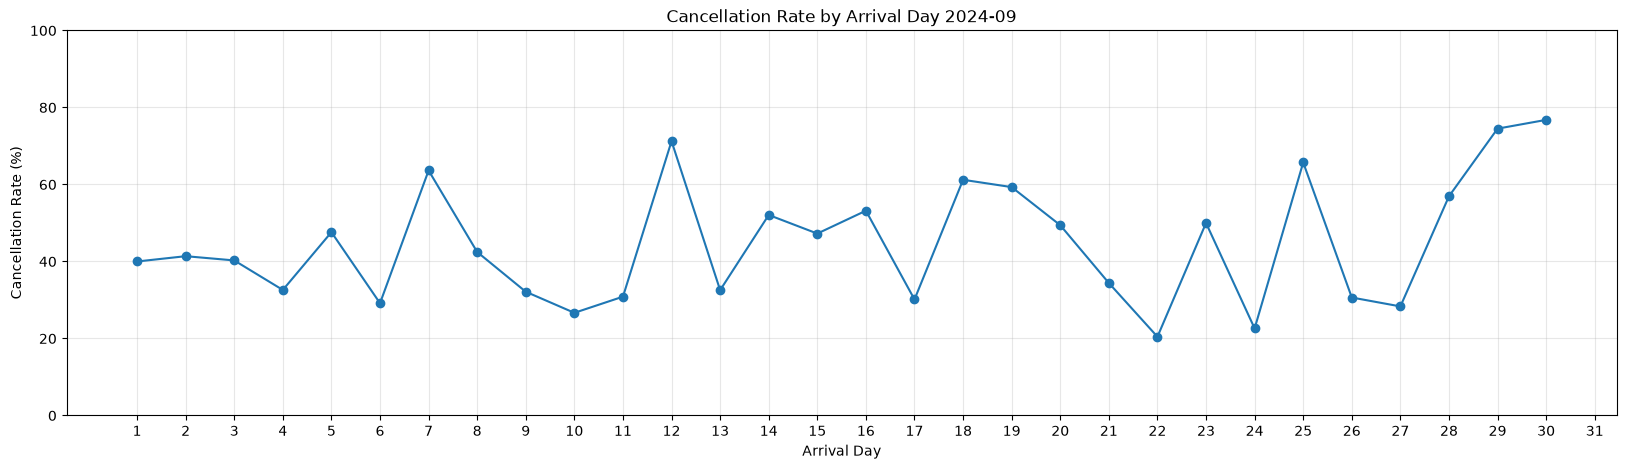

,booking_count,canceled_count,cancellation_rate
arrival_day,,,
1,80,26,32.50
2,115,45,39.13
3,88,53,60.23
4,90,50,55.56
5,72,25,34.72
6,107,46,42.99
7,34,12,35.29
8,65,25,38.46
9,122,68,55.74


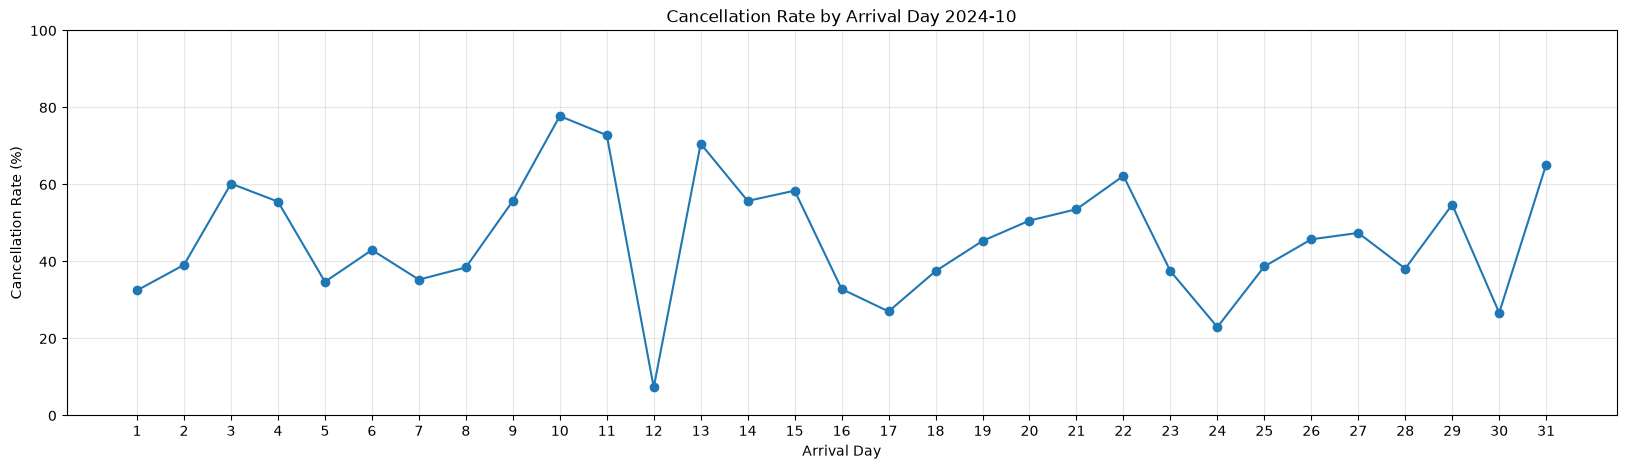

In [32]:
periods = [
    (2023, 7),
    (2024, 8),
    (2024, 9),
    (2024, 10)
]

for year, month in periods:
    # Filter data berdasarkan tahun dan bulan
    subset = train[
        (train["arrival_year"] == year) &
        (train["arrival_month"] == month)
    ]

    # Menghitung cancellation rate per tanggal
    daily = (
        subset.groupby("arrival_day")["is_canceled"]
        .mean()
        .mul(100)
        .sort_index()
    )

    # Memperlihatkan summarynya
    daily_summary = (
        subset.groupby("arrival_day")["is_canceled"]
        .agg(
            booking_count="count",
            canceled_count="sum",
            cancellation_rate="mean"
        )
    )
    
    daily_summary["cancellation_rate"] *= 100
    display(daily_summary.round(2))

    # Visualisasi
    plt.figure(figsize=(20, 5))

    plt.plot(
        daily.index.tolist(),
        daily.tolist(),
        marker="o"
    )

    plt.title(f"Cancellation Rate by Arrival Day {year}-{month:02d}")
    plt.xlabel("Arrival Day")
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(range(1, 32))
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.show()

Pada 2024, Agustus, September, Oktober memiliki tingkat pembatalan yang hampir sama yaitu 46,49%, 46,73%, dan 46,55% dengan lebih dari 2000 pemesanan pada masing-masing bulan. Untuk membandingkan tahun dengan bulan yang sama yaitu periode Juli-Desember mencatat tingkat pembatalan 14,74% pada 2023 dan 40,33% pada 2024. Selisih tersebut menunjukkan perbedaan antar periode dalam data train. 

Pada Juli 2023, 176 dari 274 pemesanan dibatalkan (64,23%). Seluruh tanggal yang mencapai 100% pembatalan hanya memiliki 1-7 pemesanan sehingga persentase hariannya mudah berubah. Pada Agustus-Oktober 2024, tingkat pembatalan setiap bulan hampir sama, tetapi tingkat pembatalan pada masing-masing tanggal berbeda-beda. Sebagai contoh pada tanggal 12 mencatat 71,25% pembatalan pada September dan 7,29% pada Oktober. Hasil ini menunjukkan bahwa analisis tingkat pembatalan perlu mempertimbangkan tahun, bulan, tanggal kedatangan, serta jumlah pemesanan pada setiap periode.

### Hubungan antar Fitur

#### Korelasi antar Fitur Numerikal

In [33]:
# Menghitung korelasi antar fitur numerik
corr_matrix = train[numerical_cols].corr(method="spearman")
display(corr_matrix.round(2))

,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
num_adults,1.00,0.03,0.11,0.13,0.17,-0.10,-0.21,0.29,0.20
num_children,0.03,1.00,0.03,0.02,-0.02,-0.03,-0.03,0.25,0.15
weekend_nights,0.11,0.03,1.00,0.02,0.10,-0.03,-0.07,-0.02,0.06
weekday_nights,0.13,0.02,0.02,1.00,0.25,-0.04,-0.12,0.02,0.05
days_before_arrival,0.17,-0.02,0.10,0.25,1.00,-0.10,-0.19,-0.03,-0.08
prior_cancellations,-0.10,-0.03,-0.03,-0.04,-0.10,1.00,0.40,-0.10,-0.02
prior_completed_bookings,-0.21,-0.03,-0.07,-0.12,-0.19,0.40,1.00,-0.18,-0.00
nightly_rate_idr,0.29,0.25,-0.02,0.02,-0.03,-0.10,-0.18,1.00,0.20
special_requests,0.20,0.15,0.06,0.05,-0.08,-0.02,-0.00,0.20,1.00


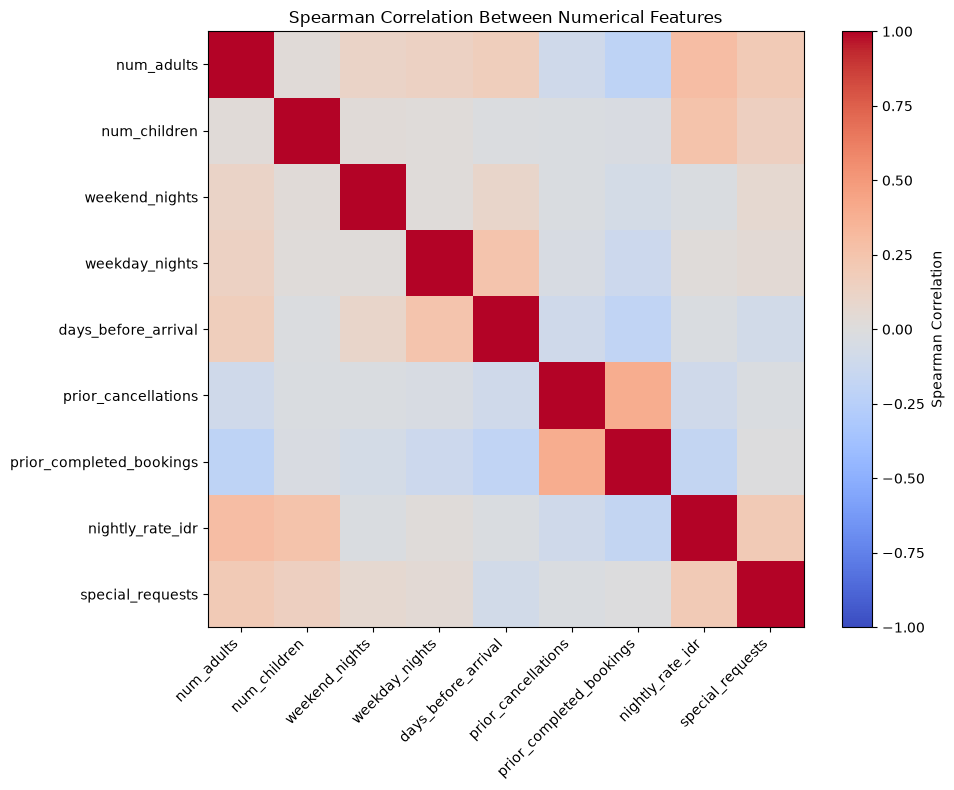

In [34]:
plt.figure(figsize=(10, 8))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Spearman Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns.tolist(),
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index.tolist()
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

Berdasarkan analisis korelasi Spearman, sebagian besar fitur numerik memiliki korelasi yang lemah. Korelasi yang bisa dijadikan pertimbangan antara lain:
- prior_cancellations - prior_completed_bookings memiliki korelasi 0,40 (positif sedang)
- num_adults - nightly_rate_idr	memiliki korelasi 0,29 (positif lemah)
- num_children - nightly_rate_idr memiliki korelasi 0,25 (positif lemah)
- weekday_nights - days_before_arrival memiliki korelasi 0,25 (positif lemah)
- num_adults - prior_completed_bookings memiliki korelasi -0,21 (negatif lemah)

Secara keseluruhan, tidak ditemukan korelasi yang kuat antar fitur numerik.

#### Korelasi antar Fitur Kategorikal

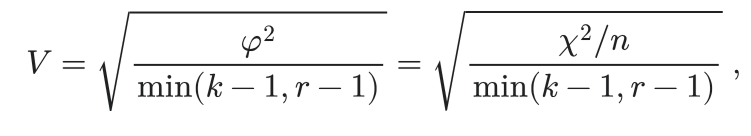

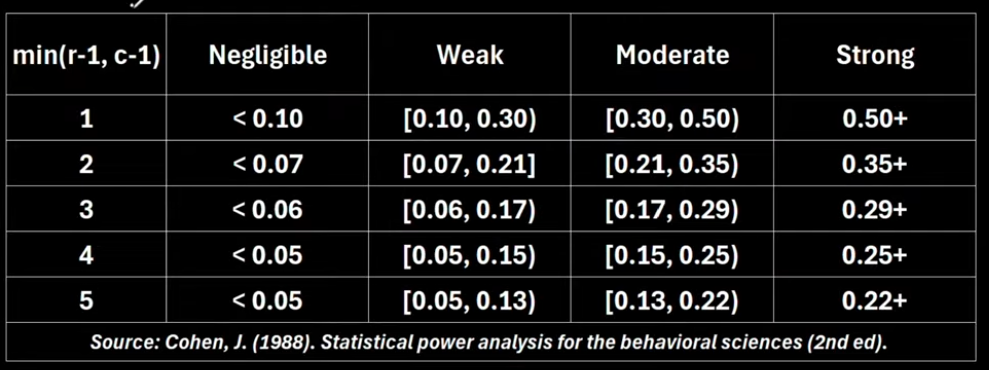

In [35]:
from scipy.stats import chi2_contingency

categorical_cols = [
    "meal_package",
    "room_category",
    "booking_channel",
    "needs_parking",
    "is_returning_guest"
]

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt((chi2 / n) / min(table.shape[0] - 1, table.shape[1] - 1))

def association_strength(v, k):
    thresholds = {
        1: (0.10, 0.30, 0.50),
        2: (0.07, 0.21, 0.35),
        3: (0.06, 0.17, 0.29),
        4: (0.05, 0.15, 0.25),
        5: (0.05, 0.13, 0.22)
    }

    weak, moderate, strong = thresholds[k]

    if v < weak:
        return "Negligible"
    elif v < moderate:
        return "Weak"
    elif v < strong:
        return "Moderate"
    else:
        return "Strong"

In [36]:
results = []

for i in range(len(categorical_cols)):
    for j in range(i + 1, len(categorical_cols)):
        col1 = categorical_cols[i]
        col2 = categorical_cols[j]

        table = pd.crosstab(train[col1], train[col2])
        k = min(table.shape[0] - 1, table.shape[1] - 1)
        value = cramers_v(train[col1], train[col2])

        results.append({
            "Feature 1": col1,
            "Feature 2": col2,
            "Cramer's V": value,
            "k": k,
            "Strength": association_strength(value, k)
        })

association_results = pd.DataFrame(results)
display(association_results.sort_values("Cramer's V", ascending=False).round(3))

,Feature 1,Feature 2,Cramer's V,k,Strength
8,booking_channel,is_returning_guest,0.460,1,Moderate
1,meal_package,booking_channel,0.227,3,Moderate
4,room_category,booking_channel,0.167,4,Moderate
0,meal_package,room_category,0.156,3,Weak
7,booking_channel,needs_parking,0.128,1,Weak
9,needs_parking,is_returning_guest,0.106,1,Weak
3,meal_package,is_returning_guest,0.074,1,Negligible
6,room_category,is_returning_guest,0.070,1,Negligible
5,room_category,needs_parking,0.050,1,Negligible
2,meal_package,needs_parking,0.032,1,Negligible


Berdasarkan analisis Cramer's V, pasangan fitur dengan asosiasi yang relatif tinggi antara lain:
- booking_channel - is_returning_guest memiliki nilai sebesar 0,460 dengan k=1 (Moderate).
- meal_package - booking_channel memiliki nilai sebesar 0,227 dengan k=3 (Moderate).
- room_category - booking_channel memiliki nilai sebesar 0,167 dengan k=4 (Moderate).

Ketiga pasangan tersebut menunjukkan bahwa booking_channel memiliki keterkaitan dengan status tamu, paket makanan, dan kategori kamar yang dipesan. Secara keseluruhan, tidak ditemukan asosiasi yang kuat antarfitur kategorikal.

## 8. Ringkasan dan Rekomendasi Pengolahan Data 

### Ringkasan EDA

Berdasarkan hasil EDA yang didapatkan, penjelasannya yaitu:

1. Distribusi Target: Dataset train memiliki 27.373 pemesanan dengan 67,23% pemesanan tidak dibatalkan dan 32,77% dibatalkan. Hal ini menunjukkan adanya ketidakseimbangan kelas pada target is_canceled.

2. Kualitas Data: Terdapat delapan fitur yang memiliki missing values dengan persentase tertinggi pada num_children sebesar 11,09%. Tidak ditemukan duplikasi ID maupun pelanggaran validitas pada nilai yang tersedia berdasarkan pemeriksaan yang dilakukan. Beberapa fitur juga memiliki outlier berdasarkan metode IQR, tetapi nilai tersebut belum tentu menunjukkan kesalahan data.

3. Distribusi Fitur: Sebagian besar pemesanan melibatkan dua orang dewasa tanpa anak, memiliki durasi menginap yang relatif pendek, menggunakan paket Breakfast, memilih kamar Type B, dilakukan melalui Online Travel Agent, serta sebagian besar tamu belum pernah menginap sebelumnya.

4. Hubungan Fitur dengan Target: Fitur days_before_arrival menunjukkan perbedaan yang cukup besar dengan median 123 hari pada pemesanan yang dibatalkan dan 38 hari pada pemesanan yang tidak dibatalkan. Pemesanan yang dibatalkan juga cenderung memiliki nightly_rate_idr lebih tinggi. Selain itu, tamu yang belum pernah menginap memiliki tingkat pembatalan lebih tinggi dibandingkan tamu yang pernah menginap, sedangkan pemesanan dengan lebih banyak special_requests cenderung memiliki tingkat pembatalan lebih rendah.

5. Hubungan Temporal dengan Target: Tingkat pembatalan berbeda antarperiode kedatangan. Pada Agustus-Oktober 2024, tingkat pembatalan bulanan berada di sekitar 46%, tetapi terdapat variasi pembatalan pada masing-masing tanggal. Perbedaan tingkat pembatalan juga terlihat antara Juli-Desember 2023 dan periode yang sama pada 2024. Namun, cakupan data belum cukup untuk memastikan adanya pola musiman yang berulang.

6. Hubungan Antarfitur: Hasil korelasi Spearman menunjukkan bahwa tidak terdapat hubungan yang kuat antar fitur numerik dengan korelasi tertinggi sebesar 0,40 antara prior_cancellations dan prior_completed_bookings. Pada fitur kategorikal, asosiasi tertinggi ditemukan antara booking_channel dan is_returning_guest dengan Cramer's V sebesar 0,460 (Moderate). Secara keseluruhan, tidak ditemukan asosiasi yang dikategorikan kuat.

### Rekomendsi Pengolahan Data

1. Melakukan pembersihan data. Terdapat delapan fitur yang memiliki nilai NaN dengan proporsi tertinggi pada num_children sebesar 11,09%. Uji imputasi untuk fitur numerik dan kategori NaN untuk meal_package serta room_category. Untuk num_children, special_requests, dan needs_parking, pertahankan informasi bahwa nilai aslinya kosong. Nilai 0 pada kolom tersebut sudah memiliki arti tersendiri. Pemeriksaan tidak menemukan ID duplikat sehingga penghapusan berdasarkan ID tidak diperlukan. Pertahankan nilai ekstrem yang masih masuk akal secara domain dan periksa nilai yang meragukan sebelum mengubahnya.
2. Melakukan transformasi data. Terapkan one-hot encoding pada meal_package, room_category, dan booking_channel karena kategorinya tidak memiliki urutan. Fitur numerik perlu distandardisasi menggunakan metode Z-Score Standardization agar perbedaan besarnya angka tidak memengaruhi cara model KNN dan Logistic Regression bekerja secara tidak semestinya. Gunakan pembagian train-validasi terstratifikasi yaitu proporsi pemesanan yang dibatalkan dan tidak dibatalkan hampir sama pada train dan validasi. Jika model nantinya digunakan untuk memprediksi pembatalan pemesanan pada periode kedepannya, maka validasi sebaiknya menggunakan data dari periode yang lebih baru daripada data train. Parameter untuk imputasi, encoding, dan standardisasi harus dipelajari dari data train saja, kemudian diterapkan pada data validation dan test. Hal ini bertujuan untuk mencegah data leakage, yaitu penggunaan informasi dari data evaluasi dalam proses pelatihan model. Bandingkan performa model awal dengan model yang menggunakan metode penanganan ketidakseimbangan kelas, seperti Class Weight atau Resampling. Bandingkan model awal dengan model dengan penanganan ketidakseimbangan kelas menggunakan metrik klasifikasi seperti Accuracy, Precision, Recall, dan F1-Score untuk menentukan apakah metode tersebut dapat meningkatkan performa model. Jika menggunakan resampling, terapkan hanya pada data train.
3. Melakukan seleksi fitur. Kolom id tetap disimpan untuk mengidentifikasi setiap pemesanan, tetapi tidak digunakan sebagai fitur untuk melatih model machine learning. Pertahankan fitur lain sebagai awalan, termasuk days_before_arrival dan nightly_rate_idr yang menunjukkan perbedaan distribusi antara pemesanan yang dibatalkan dan tidak dibatalkan berdasarkan hasil analisis Numerikal vs Target. Korelasi Spearman tertinggi sekitar 0,40 dan asosiasi Cramer’s V tertinggi 0,460 sehingga hasil antar fitur ini belum cukup untuk menghapus fitur. Uji penggunaan fitur temporal seperti arrival_year, arrival_month, dan arrival_day dengan membandingkan performa model yang menggunakan fitur temporal dengan yang tidak menggunakan fitur temporal. Hal ini diperlukan karena tingkat pembatalan berbeda antar periode, tetapi belum dapat dipastikan bahwa perbedaan tersebut membentuk pola yang konsisten.
4. Dimensionality Reduction. Gunakan seluruh fitur yang telah melalui preprocessing sebagai input model awal, kemudian jadikan hasil performanya sebagai pembanding untuk mengevaluasi apakah pengurangan dimensi dapat meningkatkan performa model dan waktu komputasi model.